In [13]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from langchain_core.messages import BaseMessage, HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv
from langgraph.checkpoint.memory import MemorySaver

from langgraph.prebuilt import ToolNode, tools_condition
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS

import requests
import math

In [14]:
load_dotenv()  

llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite",max_output_tokens=150)

In [15]:
loader = PyPDFLoader("Suraj_Jadhav_AI.pdf")
docs = loader.load()

In [16]:
len(docs)

1

In [17]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [18]:
len(chunks)

4

In [19]:
embeddings = GoogleGenerativeAIEmbeddings(
    model="gemini-embedding-001"
)
vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

In [20]:
vector_store

In [22]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [23]:
## check demo how retriever works

retriever.invoke("What is the highest qualification of student?")

[Document(id='6b2a26d7-1286-4176-9f6b-908b05536860', metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '(unspecified)', 'creationdate': '2026-10-23T16:24:19+00:00', 'author': 'Suraj Jadhav', 'keywords': '', 'moddate': '2026-10-23T16:24:19+00:00', 'subject': '(unspecified)', 'title': 'Suraj Jadhav – GenAI Resume', 'trapped': '/False', 'source': 'Suraj_Jadhav_AI.pdf', 'total_pages': 1, 'page': 0, 'page_label': '1'}, page_content='CERTIFICATIONS\nGenAI Powered Data Analytics Job Simulation – Tata (via Forage)\n February 2026\nVirtual job simulation by Tata on Forage, focused on applying Generative AI to data analytics tasks.\nPython (Basic) Certificate – HackerRank\n January 2026\nHackerRank certificate validating core Python programming skills.\nAI Tools Workshop – Be10x\n September 2026\nWorkshop covering the practical use of AI tools.'),
 Document(id='d6507ac1-21ad-4606-9e80-9de2001b8b29', metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creator': '

In [24]:
## RAG Tool
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use the tool when the user asks factual or conceptual questions
    that may be answered using the stored PDF documents.

    Args:
        query: The question or search query used to retrieve PDF content.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page","Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)

In [25]:
## Tools
import os
from getpass import getpass

search_tool = TavilySearch(
    max_results=5,
    topic="general",
    search_depth="advanced"
)

@tool
def calculator(expression: str) -> str:
    """
    Useful for simple math calculations.
    Input should be a valid math expression.
    Example: 2 + 2, math.sqrt(16), 10 * 5
    """
    try:
        allowed = {
            "math":math,
            "abs":abs,
            "round":round,
            "min":min,
            "max":max,
            "sum":sum
        }

        result = eval(expression, {"__builtins__": {}},allowed)
        return str(result)
    except Exception as e:
        return f"Calculation error: {str(e)}"


@tool
def get_stock_price(symbol: str) -> dict:
    """
    Fetch latest stock price for a given symbol (e.g. 'AAPL','TSLA')
    using Alpha Vantage with API key in the URL.
    """

    url = f"https://www.alphavantage.co/query?function=GLOBAL_QUOTE&symbol={symbol}&apikey=86NQQ2FMOAZ4IVW1"
    r = requests.get(url)
    return r.json()

In [26]:
## Make tool list

tools = [rag_tool,calculator, search_tool, get_stock_price]

## making the LLM tool-aware
llm_with_tools = llm.bind_tools(tools)

In [27]:
from langgraph.graph.message import add_messages

class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [28]:
def chat_node(state: ChatState):
    """ LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {'messages': [response]}

# executes tool calls
tool_node = ToolNode(tools)

In [29]:
graph = StateGraph(ChatState)

## add Nodes

graph.add_node('chat_node',chat_node)
graph.add_node('tools', tool_node)

In [30]:
## add edges

graph.add_edge(START, 'chat_node')
graph.add_conditional_edges('chat_node',tools_condition)
graph.add_edge('tools','chat_node')

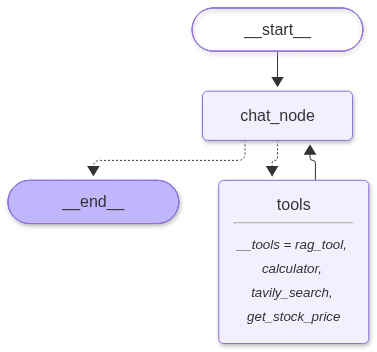

In [31]:
chatbot = graph.compile()

chatbot

In [32]:
out = chatbot.invoke({'messages' : [HumanMessage(content='which document is it about?')]})

print(out['messages'][-1].text)

This document is a **professional resume/CV** for **Suraj Jadhav**, an AI enthusiast and Master of Computer Applications (MCA) student at Savitribai Phule Pune University (expected 2027) with a background in BCA. 

It highlights:
* **Professional Summary:** Focuses on entry-level Generative AI roles with hands-on experience in building agentic AI applications.
* **Technical Skills:** Expertise in Python, SQL, JavaScript, Generative AI frameworks (LangChain, LangGraph), RAG, LLM APIs (NVIDIA, Gemini, ChatGPT, Claude), databases, and developer tools.
* **Projects:** Includes a LangGraph + Streamlit chatbot with


In [34]:
out = chatbot.invoke({'messages' : [HumanMessage(content='What are projects included in resume provided in pdf?')]})

print(out['messages'][-1].text)

Based on the resume provided in the PDF, here are the projects included:

1. **LangGraph + Streamlit Chatbot with Tools**
   * **Description:** Built a tool-using chatbot with token-by-token streaming for real-time replies. Implemented SQLite persistence using a LangGraph checkpointer so conversations are saved and reopenable. Integrated tools include DuckDuckGo search, calculator, Alpha Vantage stock prices, and weather. (In progress: human-in-the-loop, MCP client, and RAG).
   * **Tech Stack:** Python, LangGraph, Streamlit, ChatNVIDIA (gpt-oss-20b), SQLite

2. **Blog Writing Agent (Agent


In [ ]:
out = chatbot.invoke({'messages' : [HumanMessage(content='What are news today india?')]})

print(out['messages'][-1].text)

I'm currently unable to access real-time news updates due to a technical issue with the search service. Please check a trusted news outlet or aggregator app for the latest headlines in India today.


In [ ]:
thread = "thread_1"

while True:
    user_input = input("User: ")
    print("Human:", user_input)
    if user_input.lower() in ['exit', 'quit']:
        break

    initial_state['messages'].append(HumanMessage(content=user_input))
    config={"configurable": {"thread_id": thread}}
    response = chatbot.invoke(initial_state, config = config)
    print("Chatbot:", response['messages'][-1].text)

Human: quit
